In [1]:
import numpy as np
import pandas as pd
import tensorflow as tf
import matplotlib.pyplot as plt
from scipy.signal import butter, filtfilt, iirnotch, find_peaks
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv1D, MaxPooling1D, Flatten, Dense, Dropout, BatchNormalization
from tensorflow.keras.optimizers import SGD, Adam
from tensorflow.keras.callbacks import ReduceLROnPlateau, EarlyStopping


In [2]:
def preprocess_emg_signal(file_path, fs = 1000, mvc_dict=None):
    df = pd.read_csv(file_path)
    df_processed = df.copy()
    channels = [f'channel{i}' for i in range(1, 9)]
    nyq = 0.5 * fs
    b_band, a_band = butter(4, [20/nyq, 450/nyq], btype='band')
    b_low, a_low = butter(4, 10/nyq, btype='low')

    for ch in channels:
        if ch not in df.columns:
            print(f"Warning: cannot find {ch} in the file!")
            continue
        raw_sig = df[ch].fillna(0).values
        filtered = filtfilt(b_band, a_band, raw_sig)
        rectified = np.abs(filtered)
        envelope = filtfilt(b_low, a_low, rectified)
        envelope = np.maximum(envelope, 0)
        df_processed[ch] = envelope 
    for ch in channels:
        df_processed[ch] = df_processed.groupby('label')[ch].transform(
            lambda x: (x / (x.max() if x.max() > 0 else 1)) * 100
        )

        print(df_processed)

    output_file = file_path.replace('.csv', '_processed.csv')
    df_processed.to_csv(output_file, index=False)

    print("Finishing Preprocessing dataset")

    return df_processed


In [3]:
file_path = r"datasets\train\EMG-data.csv"
df = preprocess_emg_signal(file_path)
df 

          time  channel1  channel2      channel3  channel4  channel5  \
0            1  0.505663  0.000003  0.000000e+00  0.000004  0.000000   
1            5  0.540232  0.000003  4.408627e-07  0.000005  0.000000   
2            6  0.574307  0.000004  1.715085e-06  0.000006  0.000000   
3            7  0.607811  0.000005  2.980392e-06  0.000007  0.000000   
4            8  0.640667  0.000005  4.234796e-06  0.000008  0.000000   
...        ...       ...       ...           ...       ...       ...   
4237902  50962  1.788038  0.000005  7.649281e-06  0.000008  0.000035   
4237903  50963  1.784848  0.000005  7.643663e-06  0.000008  0.000035   
4237904  50964  1.782188  0.000005  7.638959e-06  0.000008  0.000035   
4237905  50965  1.780000  0.000005  7.635074e-06  0.000008  0.000035   
4237906  50966  1.778226  0.000005  7.631911e-06  0.000008  0.000035   

             channel6      channel7      channel8  class  label  
0        4.586132e-07  1.549889e-07  0.000000e+00      0      1  
1  

,time,channel1,channel2,channel3,channel4,channel5,channel6,channel7,channel8,class,label
0,1,0.505663,0.426684,0.000000,0.569724,0.000000,0.098621,0.035534,0.000000,0,1
1,5,0.540232,0.521757,0.077848,0.747488,0.000000,0.207517,0.066253,0.000000,0,1
2,6,0.574307,0.618733,0.302852,0.923943,0.000000,0.314503,0.097629,0.000000,0,1
3,7,0.607811,0.717485,0.526282,1.098786,0.000000,0.419383,0.129625,0.000000,0,1
4,8,0.640667,0.817878,0.747786,1.271718,0.000000,0.521969,0.162198,0.008943,0,1
...,...,...,...,...,...,...,...,...,...,...,...
4237902,50962,1.788038,1.957604,4.085815,1.574949,5.676281,4.573566,3.862965,4.831329,0,36
4237903,50963,1.784848,1.957495,4.082814,1.576233,5.682195,4.571260,3.867166,4.830561,0,36
4237904,50964,1.782188,1.957413,4.080302,1.577300,5.687095,4.569356,3.870658,4.829887,0,36
4237905,50965,1.780000,1.957352,4.078227,1.578175,5.691099,4.567802,3.873519,4.829305,0,36


In [4]:
def create_sliding_windows(data, window_size, step_size, channels):
    X, y = [], []
    for (subj, cls_val), group in data.groupby(['label', 'class']):
        group_vals = group[channels].values

        for i in range(0, len(group_vals) - window_size + 1, step_size):
            window = group_vals[i : i + window_size]
            X.append(window)
            y.append(cls_val)
            
    return np.array(X), np.array(y)

In [5]:
def prepare_emg_data_for_cnn(csv_file, window_size=200, step_size=50):
    df = pd.read_csv(csv_file)
    df = df[df['class'] != 0]
    df['class'] = df['class'] - 1

    train_subjects = list(range(1, 31))
    test_subjects = list(range(31, 37))

    train_df = df[df['label'].isin(train_subjects)]
    test_df = df[df['label'].isin(test_subjects)]

    channels = [f'channel{i}' for i in range(1, 9)]

    print("Slicing Training set")
    X_train, y_train = create_sliding_windows(train_df, window_size, step_size, channels)

    print("Slicing Testing set")
    X_test, y_test = create_sliding_windows(test_df, window_size, step_size, channels)

    print(f"X_train shape: {X_train.shape}")
    print(f"y_train shape: {y_train.shape}")
    print(f"X_test shape:  {X_test.shape}")
    print(f"y_test shape:  {y_test.shape}")

    return X_train, y_train, X_test, y_test

X_train, y_train, X_test, y_test = prepare_emg_data_for_cnn('datasets/train/EMG-data_processed.csv', window_size=200, step_size=50)

Slicing Training set
Slicing Testing set
X_train shape: (24726, 200, 8)
y_train shape: (24726,)
X_test shape:  (4769, 200, 8)
y_test shape:  (4769,)


In [6]:
def build_and_train_cnn(X_train, y_train, X_test, y_test, num_classes=7):
    input_shape = (X_train.shape[1], X_train.shape[2])
    model = Sequential([
        Conv1D(filters=32, kernel_size=3, kernel_regularizer=tf.keras.regularizers.l2(1e-4), activation='relu', input_shape=input_shape),
        BatchNormalization(),
        MaxPooling1D(pool_size=2),

        Conv1D(filters=64, kernel_size=3, kernel_regularizer=tf.keras.regularizers.l2(1e-4), activation='relu'),
        BatchNormalization(),
        MaxPooling1D(pool_size=2),

        Flatten(),
        Dense(128, activation='relu', kernel_regularizer=tf.keras.regularizers.l2(1e-4)),
        Dropout(0.3),
        Dense(num_classes, activation='softmax')
    ])

    custom_optimizer = Adam(
        learning_rate=0.0005,
        beta_1=0.9,
        beta_2=0.999,
        epsilon=1e-7
    )
    model.compile(optimizer=custom_optimizer, 
              loss='sparse_categorical_crossentropy', 
              metrics=['accuracy'])
    callbacks = [
        ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=4, min_lr=1e-5, verbose=1),
        EarlyStopping(monitor='val_loss', patience=10, restore_best_weights=True)
    ]



    print("============== Model Summary: ==============")
    model.summary()

    print("Starting Training......")

    history = model.fit(X_train, y_train, 
                        epochs=50,       
                        batch_size=64,      
                        validation_data=(X_test, y_test),
                        callbacks=callbacks
               )
    
    test_loss, test_acc = model.evaluate(X_test, y_test)
    print(f"Test accuracy: {test_acc * 100:.2f}%")
    
    return model, history

model, history = build_and_train_cnn(X_train, y_train, X_test, y_test, num_classes=7)

c:\Users\Admin\AppData\Local\Programs\Python\Python312\Lib\site-packages\keras\src\layers\convolutional\base_conv.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


============== Model Summary: ==============


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv1d (Conv1D)                 │ (None, 198, 32)        │           800 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 198, 32)        │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d (MaxPooling1D)    │ (None, 99, 32)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_1 (Conv1D)               │ (None, 97, 64)         │         6,208 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 97, 64)         │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d_1 (MaxPooling1D)  │ (None, 48, 64)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 3072)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       393,344 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 7)              │           903 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 401,639 (1.53 MB)

 Trainable params: 401,447 (1.53 MB)

 Non-trainable params: 192 (768.00 B)

Starting Training......
Epoch 1/50
387/387 ━━━━━━━━━━━━━━━━━━━━ 9s 16ms/step - accuracy: 0.7491 - loss: 0.8041 - val_accuracy: 0.8805 - val_loss: 0.3554 - learning_rate: 5.0000e-04
Epoch 2/50
387/387 ━━━━━━━━━━━━━━━━━━━━ 6s 15ms/step - accuracy: 0.8534 - loss: 0.4333 - val_accuracy: 0.8790 - val_loss: 0.3685 - learning_rate: 5.0000e-04
Epoch 3/50
387/387 ━━━━━━━━━━━━━━━━━━━━ 6s 15ms/step - accuracy: 0.8701 - loss: 0.3777 - val_accuracy: 0.8857 - val_loss: 0.3491 - learning_rate: 5.0000e-04
Epoch 4/50
387/387 ━━━━━━━━━━━━━━━━━━━━ 6s 17ms/step - accuracy: 0.8770 - loss: 0.3581 - val_accuracy: 0.8874 - val_loss: 0.3219 - learning_rate: 5.0000e-04
Epoch 5/50
387/387 ━━━━━━━━━━━━━━━━━━━━ 6s 15ms/step - accuracy: 0.8970 - loss: 0.3090 - val_accuracy: 0.8809 - val_loss: 0.3651 - learning_rate: 5.0000e-04
Epoch 6/50
387/387 ━━━━━━━━━━━━━━━━━━━━ 6s 15ms/step - accuracy: 0.8982 - loss: 0.3013 - val_accuracy: 0.8910 - val_loss: 0.3320 - learning_rate: 5.0000e-04
Epoch 7/50
387/387 ━━━━━━━━━━━━━━━

### 3 Channel Dataset

In [7]:
import os
import glob
from sklearn.model_selection import train_test_split
from tensorflow.keras.layers import Input, BatchNormalization, Dense, Dropout, Add, Activation, Bidirectional, LSTM
from tensorflow.keras.models import Model

def butter_bandpass(lowcut, highcut, fs, order=4):
    nyq = 0.5 * fs
    low = max(lowcut / nyq, 0.001)
    high = min(highcut / nyq, 0.999)
    b, a = butter(order, [low, high], btype='band')
    return b, a

def butter_lowpass(cutoff, fs, order=4):
    nyq = 0.5 * fs
    cut = min(cutoff / nyq, 0.999)
    b, a = butter(order, cut, btype='low')
    return b, a


def preprocess_emg_signal(df, fs=1000):

    df_processed = df.copy()
    channels = [f'Channel {i}' for i in range(1, 4)]
    b_band, a_band = butter_bandpass(20, 450, fs, order=4)
    b_low, a_low = butter_lowpass(10, fs, order=4)
    b_notch, a_notch = iirnotch(w0=50, Q=30, fs=fs)

    for ch in channels:
        if ch not in df.columns:
            continue
        raw_sig = df[ch].fillna(0).values.astype(np.float32)
       
        sig_notch = filtfilt(b_notch, a_notch, raw_sig)
      
        filtered = filtfilt(b_band, a_band, sig_notch)
        
        rectified = np.abs(filtered)
      
        envelope = filtfilt(b_low, a_low, rectified)
        envelope = np.maximum(envelope, 0.0)
        df_processed[ch] = envelope

    return df_processed

def load_and_preprocess_dataset(base_dir="datasets/train", fs=1000):

    gesture_map = {
        '1st_Gesture_Resting': 0,
        '2nd_Gesture_Fist': 1,
        '4th_Gesture_Open_Hand': 2,
        '7th_Gesture_Pointing': 3
    }
    trials = []
    channels = ['Channel 1', 'Channel 2', 'Channel 3']
    
    for folder, cls_idx in gesture_map.items():
        files = sorted(glob.glob(os.path.join(base_dir, folder, "*.csv")))
        for f in files:
            df = pd.read_csv(f)
            df_proc = preprocess_emg_signal(df, fs=fs)
            trials.append({
                'file': os.path.basename(f),
                'signal': df_proc[channels].values,
                'class': cls_idx
            })
            
    print(f"Preprocessing finish: {len(trials)} trials ")
    return trials


In [8]:
trials = load_and_preprocess_dataset('datasets/train')


Preprocessing finish: 300 trials 


In [9]:
def create_sliding_windows(trials, window_size=200, step_size=25):
    X, y = [], []
    for t in trials:
        sig = t['signal']
        cls_val = t['class']
        for i in range(0, len(sig) - window_size + 1, step_size):
            X.append(sig[i : i + window_size])
            y.append(cls_val)
    return np.array(X, dtype=np.float32), np.array(y, dtype=np.int32)

train_trials, temp_trials = train_test_split(trials, test_size=0.3, random_state=42, stratify=[t['class'] for t in trials])
val_trials, test_trials = train_test_split(temp_trials, test_size=0.5, random_state=42, stratify=[t['class'] for t in temp_trials])

print(f"Trials Number: Train={len(train_trials)}, Val={len(val_trials)}, Test={len(test_trials)}")

X_train, y_train = create_sliding_windows(train_trials, window_size=200, step_size=25)
X_val, y_val = create_sliding_windows(val_trials, window_size=200, step_size=25)
X_test, y_test = create_sliding_windows(test_trials, window_size=200, step_size=25)

mean = np.mean(X_train, axis=(0, 1), keepdims=True)
std = np.std(X_train, axis=(0, 1), keepdims=True) + 1e-8

X_train = (X_train - mean) / std
X_val = (X_val - mean) / std
X_test = (X_test - mean) / std

print(f"X_train shape: {X_train.shape} | y_train shape: {y_train.shape}")
print(f"X_val shape:   {X_val.shape}   | y_val shape:   {y_val.shape}")
print(f"X_test shape:  {X_test.shape}  | y_test shape:  {y_test.shape}")




Trials Number: Train=210, Val=45, Test=45
X_train shape: (27930, 200, 3) | y_train shape: (27930,)
X_val shape:   (5985, 200, 3)   | y_val shape:   (5985,)
X_test shape:  (5985, 200, 3)  | y_test shape:  (5985,)


### Feature Extraction (Hudgins Time-Domain Features)
1. **MAV (Mean Absolute Value)**
2. **RMS (Root Mean Square)**
3. **WL (Waveform Length)**
4. **ZC (Zero Crossing)**
5. **SSC (Slope Sign Change)**


In [10]:
from sklearn.preprocessing import StandardScaler

def extract_hudgins_features(window, eps=1e-4):

    d = np.diff(window, axis=0)
    mav = np.mean(np.abs(window), axis=0)
    rms = np.sqrt(np.mean(window ** 2, axis=0))
    wl = np.sum(np.abs(d), axis=0)
    zc = np.sum((window[:-1] * window[1:] < 0) & (np.abs(window[:-1] - window[1:]) >= eps), axis=0)
    ssc = np.sum((d[:-1] * d[1:] < 0) & ((np.abs(d[:-1]) >= eps) | (np.abs(d[1:]) >= eps)), axis=0)
    
    return np.concatenate([mav, rms, wl, zc, ssc])

def extract_features_from_windows(X_windows):
    X_feats = [extract_hudgins_features(w) for w in X_windows]
    return np.array(X_feats, dtype=np.float32)

print("Extracting Hudgins features from sliding windows...")
X_train_feat = extract_features_from_windows(X_train)
X_val_feat   = extract_features_from_windows(X_val)
X_test_feat  = extract_features_from_windows(X_test)


scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train_feat)
X_val_scaled   = scaler.transform(X_val_feat)
X_test_scaled  = scaler.transform(X_test_feat)

print(f"X_train_scaled shape: {X_train_scaled.shape} (Features per window: {X_train_scaled.shape[1]})")
print(f"X_val_scaled shape:   {X_val_scaled.shape}")
print(f"X_test_scaled shape:  {X_test_scaled.shape}")


Extracting Hudgins features from sliding windows...
X_train_scaled shape: (27930, 15) (Features per window: 15)
X_val_scaled shape:   (5985, 15)
X_test_scaled shape:  (5985, 15)


### TensorFlow Lightweight Feature Classifier (MLP + Dropout + Adam + MiniBatch)

- **Dense Layers**
- **Dropout + BatchNormalization** 
- **Mini-Batch GD**, **Adam**, **EarlyStopping**.

In [11]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout, BatchNormalization
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import ReduceLROnPlateau, EarlyStopping

def build_hudgins_mlp(input_dim=15, num_classes=4):
    model = Sequential([
        Dense(64, activation='relu', input_shape=(input_dim,)),
        BatchNormalization(),
        Dropout(0.3),
        
        Dense(32, activation='relu'),
        BatchNormalization(),
        Dropout(0.2),
        
        Dense(num_classes, activation='softmax')
    ], name="EMG_Hudgins_MLP")
    
    model.compile(
        optimizer=Adam(learning_rate=0.001),
        loss='sparse_categorical_crossentropy',
        metrics=['accuracy']
    )
    return model

mlp_model = build_hudgins_mlp(input_dim=X_train_scaled.shape[1], num_classes=4)
mlp_model.summary()


c:\Users\Admin\AppData\Local\Programs\Python\Python312\Lib\site-packages\keras\src\layers\core\dense.py:87: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "EMG_Hudgins_MLP"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_2 (Dense)                 │ (None, 64)             │         1,024 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 64)             │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 32)             │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 4)              │           132 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,620 (14.14 KB)

 Trainable params: 3,428 (13.39 KB)

 Non-trainable params: 192 (768.00 B)

In [12]:
callbacks = [
    ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=4, min_lr=1e-5, verbose=1),
    EarlyStopping(monitor='val_loss', patience=10, restore_best_weights=True, verbose=1)
]

print("Starting Training TensorFlow MLP on Hudgins Features...")
history_mlp = mlp_model.fit(
    X_train_scaled, y_train,
    validation_data=(X_val_scaled, y_val),
    epochs=50,
    batch_size=64, # Mini-batch optimization
    callbacks=callbacks,
    verbose=1
)

test_loss, test_acc = mlp_model.evaluate(X_test_scaled, y_test, verbose=0)
print(f"\n>>> TF MLP TEST SET ACCURACY: {test_acc * 100:.2f}% (Loss: {test_loss:.4f})")


Starting Training TensorFlow MLP on Hudgins Features...
Epoch 1/50
437/437 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - accuracy: 0.5873 - loss: 1.0514 - val_accuracy: 0.7876 - val_loss: 0.5674 - learning_rate: 0.0010
Epoch 2/50
437/437 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.7141 - loss: 0.6948 - val_accuracy: 0.8018 - val_loss: 0.5255 - learning_rate: 0.0010
Epoch 3/50
437/437 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.7358 - loss: 0.6396 - val_accuracy: 0.8112 - val_loss: 0.5009 - learning_rate: 0.0010
Epoch 4/50
437/437 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.7442 - loss: 0.6115 - val_accuracy: 0.8140 - val_loss: 0.4879 - learning_rate: 0.0010
Epoch 5/50
437/437 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.7495 - loss: 0.6009 - val_accuracy: 0.8164 - val_loss: 0.4725 - learning_rate: 0.0010
Epoch 6/50
437/437 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.7616 - loss: 0.5850 - val_accuracy: 0.8232 - val_loss: 0.4570 - learning_rate: 0.0010
Epoch 7/50
437/437 ━━━━━━━━━━━━━

188/188 ━━━━━━━━━━━━━━━━━━━━ 0s 880us/step

===== CLASSIFICATION REPORT (TF MLP) =====
                precision    recall  f1-score   support

  Resting (G1)     0.9193    0.9919    0.9542      1596
     Fist (G2)     0.8881    0.6726    0.7655      1463
Open Hand (G4)     0.8137    0.7491    0.7801      1463
 Pointing (G7)     0.6438    0.7956    0.7117      1463

      accuracy                         0.8065      5985
     macro avg     0.8162    0.8023    0.8029      5985
  weighted avg     0.8185    0.8065    0.8062      5985



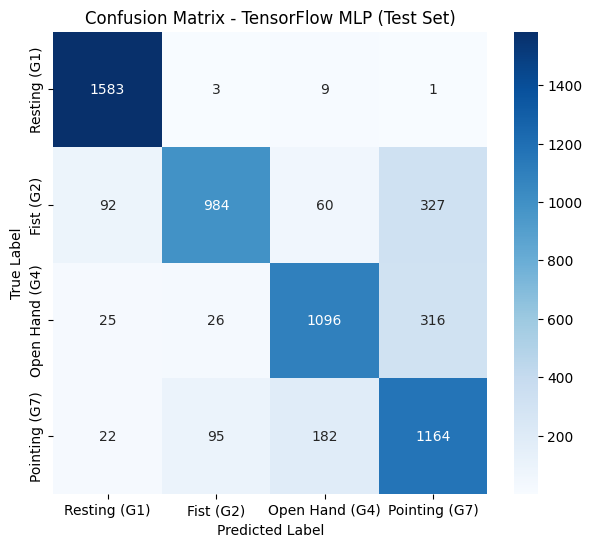

In [13]:
import seaborn as sns
from sklearn.metrics import classification_report, confusion_matrix

target_names = ['Resting (G1)', 'Fist (G2)', 'Open Hand (G4)', 'Pointing (G7)']
y_pred_probs = mlp_model.predict(X_test_scaled)
y_pred = np.argmax(y_pred_probs, axis=1)

print("\n===== CLASSIFICATION REPORT (TF MLP) =====")
print(classification_report(y_test, y_pred, target_names=target_names, digits=4))

cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(7, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', 
            xticklabels=target_names, yticklabels=target_names)
plt.title('Confusion Matrix - TensorFlow MLP (Test Set)')
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.show()


### Traditional Machine Learning Benchmark (LDA, SVM, Random Forest)

In [14]:
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score

models_classic = {
    'LDA': LinearDiscriminantAnalysis(),
    'SVM (RBF Kernel)': SVC(C=10.0, gamma='scale', random_state=42),
    'Random Forest (100 trees)': RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=1)
}

print("=== Traditional Machine Learning Results (Test Set) ===")
for name, clf in models_classic.items():
    clf.fit(X_train_scaled, y_train)
    acc = accuracy_score(y_test, clf.predict(X_test_scaled))
    print(f"{name:26s} Test Accuracy: {acc * 100:.2f}%")

print(f"{'TensorFlow MLP':26s} Test Accuracy: {test_acc * 100:.2f}%")


=== Traditional Machine Learning Results (Test Set) ===
LDA                        Test Accuracy: 67.20%
SVM (RBF Kernel)           Test Accuracy: 80.84%
Random Forest (100 trees)  Test Accuracy: 82.36%
TensorFlow MLP             Test Accuracy: 80.65%
